        # Lesson 8.5 · Project 1: Handwritten Digit Recognition
        ### From pixels to predictions with an ANN, then a CNN

        | | |
        |---|---|
        | ⏱️ **Time** | about 100 minutes |
        | 📚 **Before you start** | Lessons 8.1 – 8.4 |
        | 🧪 **Format** | lesson → worked examples → exercises with hints → recap |

        ## 🎯 What you will be able to do after this notebook
        - Run a complete **image-classification workflow**: explore → split → baseline → ANN → CNN → error analysis
- Read **accuracy, confusion matrices** and look at the images the model gets *wrong*
- Build a small **CNN** with `Conv2d`, `MaxPool2d` and understand why it beats a fully-connected net

> 🌾 **The story so far.** The cooperative's clerks write quantities and prices on paper delivery slips. Digitising them means reading handwritten digits: the 'hello world' of deep learning, and the perfect first project.

In [1]:
import sys, pathlib, warnings
# Find the course folder (works no matter where Jupyter was started)
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "src" / "agrilab.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import agrilab as ag          # our helper library: src/agrilab.py

import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
torch.set_num_threads(1)
warnings.filterwarnings("ignore")   # (after imports: statsmodels re-enables its own warnings when imported)
ag.setup_plots()
ag.set_seed(42)
print("Setup complete. Course folder:", ROOT.name)

Setup complete. Course folder: course


## 1 · The data

We use scikit-learn's bundled **digits** set: 1,797 grayscale images of 8×8 pixels, pixel values 0–16, ten classes (0–9). It ships with scikit-learn, so it works offline.
(A real-MNIST cell (70,000 images of 28×28) is provided at the end for when you have internet.)

images: (1797, 8, 8) | labels: (1797,) | pixel range: 0.0 - 16.0
class counts: [178 182 177 183 181 182 181 179 174 180]


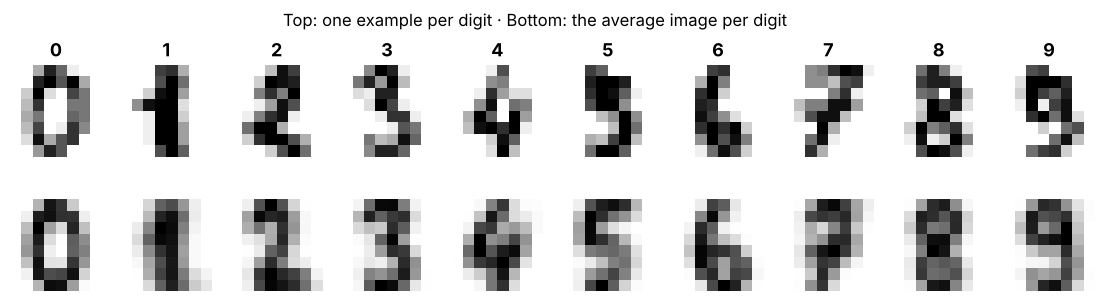

In [2]:
digits = load_digits()
X_img, y = digits.images, digits.target                      # (1797, 8, 8), (1797,)
print("images:", X_img.shape, "| labels:", y.shape, "| pixel range:", X_img.min(), "-", X_img.max())
print("class counts:", np.bincount(y))

fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for d in range(10):
    axes[0, d].imshow(X_img[y == d][0], cmap="gray_r"); axes[0, d].set_title(str(d)); axes[0, d].axis("off")
    axes[1, d].imshow(X_img[y == d].mean(axis=0), cmap="gray_r"); axes[1, d].axis("off")
axes[0, 0].set_ylabel("example"); plt.suptitle("Top: one example per digit · Bottom: the average image per digit", y=1.02); plt.show()

---
### 🧩 Exercise 1: Explore before you model  ⭐

1. `counts`: NumPy array with the number of images per digit (length 10).
2. `most_common`: the digit that occurs most often.
3. `mean_eight`: the average image of all the **8**s (shape `(8, 8)`).
4. `brightest_digit`: the digit whose average image has the largest **total ink** (sum of pixel values).

<details><summary>💡 Hint 1: gentle nudge</summary>

`np.bincount(y)` counts per class; `counts.argmax()` is the most common.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`X_img[y == 8].mean(axis=0)` averages over the images of class 8.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`np.array([X_img[y == d].mean(axis=0).sum() for d in range(10)]).argmax()`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [3]:
counts = np.bincount(y)
most_common = int(counts.argmax())
mean_eight = X_img[y == 8].mean(axis=0)
brightest_digit = int(np.array([X_img[y == d].mean(axis=0).sum() for d in range(10)]).argmax())
print(counts, most_common, mean_eight.shape, brightest_digit)

[178 182 177 183 181 182 181 179 174 180] 3 (8, 8) 8


In [4]:
ag.check("counts: 10 classes, 1797 images", counts is not None and len(counts) == 10 and counts.sum() == 1797)
ag.check("most_common is the arg-max of counts", most_common == int(np.bincount(y).argmax()))
ag.check("mean_eight is an 8x8 image", mean_eight is not None and mean_eight.shape == (8, 8))
ag.check("brightest digit (most ink) is 8", brightest_digit == 8, "sum pixel values of each class-average image")

✅  counts: 10 classes, 1797 images
✅  most_common is the arg-max of counts
✅  mean_eight is an 8x8 image
✅  brightest digit (most ink) is 8


True

## 2 · Split, scale, baseline

Stratified **train / validation / test** split (60/20/20): every digit appears in each part in equal proportion. Pixel values are scaled to [0, 1].
Baseline: **logistic regression** on the 64 raw pixels: the bar any neural network must clear.

In [5]:
Xf = (X_img.reshape(len(X_img), -1) / 16.0).astype(np.float32)
Xtmp, Xte_, ytmp, yte_ = train_test_split(Xf, y, test_size=0.2, stratify=y, random_state=0)
Xtr_, Xva_, ytr_, yva_ = train_test_split(Xtmp, ytmp, test_size=0.25, stratify=ytmp, random_state=0)
print("train / val / test:", len(Xtr_), len(Xva_), len(Xte_))

logreg = LogisticRegression(max_iter=2000).fit(Xtr_, ytr_)
print(f"logistic regression: val acc {logreg.score(Xva_, yva_):.3f} | test acc {logreg.score(Xte_, yte_):.3f}")

T = lambda a, dt=torch.float32: torch.tensor(a, dtype=dt)
Xtr, Xva, Xte = T(Xtr_), T(Xva_), T(Xte_)
ytr, yva, yte = T(ytr_, torch.long), T(yva_, torch.long), T(yte_, torch.long)

train / val / test: 1077 360 360
logistic regression: val acc 0.967 | test acc 0.964


## 3 · A fully-connected network (ANN)

Flatten the image to 64 numbers and feed a stack of `Linear + ReLU` layers; the final layer has 10 outputs (**logits**) and we use `CrossEntropyLoss`.
Our reusable training helper uses **early stopping on validation accuracy** and restores the best weights.

In [6]:
def train_clf(model, Xtr, ytr, Xva, yva, epochs=60, lr=2e-3, batch=64, patience=10, wd=1e-4, seed=0, verbose=True, reshape=None):
    """Train a classifier; returns (model with best weights, history). reshape: optional function applied to each X batch (e.g. to add a channel dim)."""
    torch.manual_seed(seed)
    prep = reshape or (lambda t: t)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd); lossf = nn.CrossEntropyLoss()
    loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=batch, shuffle=True)
    best, best_state, wait, hist = -1, None, 0, []
    for ep in range(epochs):
        model.train()
        for xb, yb in loader:
            opt.zero_grad(); lossf(model(prep(xb)), yb).backward(); opt.step()
        model.eval()
        with torch.no_grad():
            tl = lossf(model(prep(Xtr)), ytr).item(); out = model(prep(Xva)); vl = lossf(out, yva).item(); va = (out.argmax(1) == yva).float().mean().item()
        hist.append((tl, vl, va))
        if va > best: best, best_state, wait = va, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(best_state); model.eval()
    if verbose: print(f"  stopped after {len(hist)} epochs | best validation accuracy {best:.3f}")
    return model, np.array(hist)

def accuracy(model, X, y, reshape=None):
    model.eval()
    with torch.no_grad(): return (model((reshape or (lambda t: t))(X)).argmax(1) == y).float().mean().item()

torch.manual_seed(0)
ann = nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Dropout(0.2), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 10))
ann, h_ann = train_clf(ann, Xtr, ytr, Xva, yva)
print(f"ANN: parameters {sum(p.numel() for p in ann.parameters()):,} | test accuracy {accuracy(ann, Xte, yte):.3f}")

  stopped after 33 epochs | best validation accuracy 0.972
ANN: parameters 17,226 | test accuracy 0.972


---
### 🧩 Exercise 2: Your own ANN  ⭐

Build `my_ann`: `nn.Sequential` with layers **64 → 32 → 16 → 10** (ReLU between, no activation after the last), train it with `train_clf(my_ann, Xtr, ytr, Xva, yva, verbose=False)`
and store the test accuracy in `my_ann_acc` and the parameter count in `my_ann_params`.

<details><summary>💡 Hint 1: gentle nudge</summary>

`nn.Sequential(nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 10))`

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`my_ann, _ = train_clf(my_ann, ...)` returns the model with the best weights.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Parameters: `sum(p.numel() for p in my_ann.parameters())` (64·32+32 + 32·16+16 + 16·10+10 = 2,778).

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [7]:
torch.manual_seed(1)
my_ann = nn.Sequential(nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 10))
my_ann, _ = train_clf(my_ann, Xtr, ytr, Xva, yva, verbose=False)
my_ann_acc = accuracy(my_ann, Xte, yte)
my_ann_params = sum(p.numel() for p in my_ann.parameters())
print(my_ann_params, round(my_ann_acc, 3))

2778 0.953


In [8]:
ag.check("2,778 parameters", my_ann_params == 2778)
ag.check("test accuracy above 93 %", my_ann_acc is not None and my_ann_acc > 0.93)

✅  2,778 parameters
✅  test accuracy above 93 %


True

## 4 · Error analysis: where does it fail?

A single accuracy number hides *which* mistakes happen. The **confusion matrix** counts, for every true class (rows), what the model predicted (columns). Off-diagonal cells are errors.

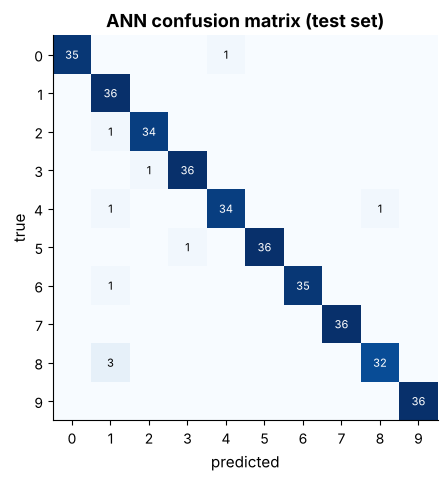

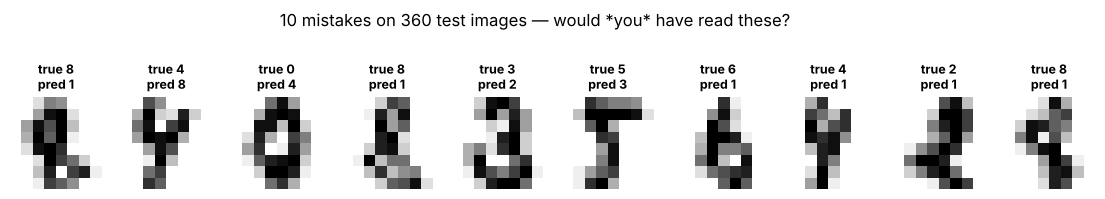

In [9]:
with torch.no_grad(): pred_ann = ann(Xte).argmax(1).numpy()
cm_ref = confusion_matrix(yte.numpy(), pred_ann)
fig, ax = plt.subplots(figsize=(5.5, 5)); im = ax.imshow(cm_ref, cmap="Blues")
for i in range(10):
    for j in range(10):
        if cm_ref[i, j]: ax.text(j, i, cm_ref[i, j], ha="center", va="center", color="white" if cm_ref[i, j] > cm_ref.max() / 2 else "black", fontsize=8)
ax.set(xticks=range(10), yticks=range(10), xlabel="predicted", ylabel="true", title="ANN confusion matrix (test set)"); ax.grid(False); plt.show()

wrong = np.where(pred_ann != yte.numpy())[0]
fig, axes = plt.subplots(1, min(10, len(wrong)), figsize=(14, 2.2))
for ax, i in zip(np.atleast_1d(axes), wrong[:10]):
    ax.imshow(Xte[i].reshape(8, 8), cmap="gray_r"); ax.set_title(f"true {yte[i].item()}\npred {pred_ann[i]}", fontsize=9); ax.axis("off")
plt.suptitle(f"{len(wrong)} mistakes on {len(yte)} test images: would *you* have read these?", y=1.1); plt.show()

---
### 🧩 Exercise 3: Build the confusion matrix yourself  ⭐⭐

Using `yte` (true labels) and `pred_ann` (predictions) as NumPy arrays, build `cm`: a `(10, 10)` integer matrix with `cm[true, pred]` = count: **without** `sklearn`.
Then find `worst_pair`: the `(true, predicted)` tuple of the most frequent **off-diagonal** cell.

<details><summary>💡 Hint 1: gentle nudge</summary>

`cm = np.zeros((10, 10), dtype=int)`; loop over `zip(true, pred)` and do `cm[t, p] += 1` (or use `np.add.at(cm, (true, pred), 1)`).

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

Copy `cm`, set the diagonal to 0: `off = cm.copy(); np.fill_diagonal(off, 0)`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`i, j = np.unravel_index(off.argmax(), off.shape)`; `worst_pair = (int(i), int(j))`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [10]:
true = yte.numpy()
cm = np.zeros((10, 10), dtype=int)
np.add.at(cm, (true, pred_ann), 1)
off = cm.copy(); np.fill_diagonal(off, 0)
i, j = np.unravel_index(off.argmax(), off.shape)
worst_pair = (int(i), int(j))
print("most common confusion: true", worst_pair[0], "predicted as", worst_pair[1])

most common confusion: true 8 predicted as 1


In [11]:
ag.check("matches sklearn's confusion matrix", cm is not None and np.array_equal(cm, cm_ref))
ag.check("worst_pair is a (true, pred) tuple with true != pred", isinstance(worst_pair, tuple) and worst_pair[0] != worst_pair[1])

✅  matches sklearn's confusion matrix
✅  worst_pair is a (true, pred) tuple with true != pred


True

---
## 5 · Convolutional neural networks (CNN)

A fully-connected net treats the image as 64 *unrelated* numbers: shift the digit one pixel and every input changes. A **convolution** instead slides a small **filter** (e.g. 3×3) across the image:
the *same* few weights detect the *same* pattern (an edge, a curve) *anywhere*.

| Idea | Benefit |
|---|---|
| **Local connectivity** (3×3 windows) | learns local patterns: strokes, corners |
| **Weight sharing** (same filter everywhere) | far fewer parameters; **translation equivariance** |
| **Pooling** (`MaxPool2d`) | shrinks the map, adds tolerance to small shifts |
| **Stacking** | early layers = edges, later layers = parts, then whole digits |

Shapes flow as `(batch, channels, height, width)`: `(N,1,8,8) → Conv(1→16) → (N,16,8,8) → Pool → (N,16,4,4) → Conv(16→32) → (N,32,4,4) → Pool → (N,32,2,2) → Flatten → 128 → Linear → 10`.
Lesson 8.6 opens the black box fully; here we just build and train one.

---
### 🧩 Exercise 4: Build a CNN  ⭐⭐

Define `DigitCNN(nn.Module)` implementing exactly the shape flow above:
`Conv2d(1,16,3,padding=1)` → ReLU → `MaxPool2d(2)` → `Conv2d(16,32,3,padding=1)` → ReLU → `MaxPool2d(2)` → `Flatten` → `Linear(128, 10)`.
Train it (`train_clf` with `reshape=lambda t: t.view(-1, 1, 8, 8)`) and store `cnn`, its test accuracy `cnn_acc` and parameter count `cnn_params`.

<details><summary>💡 Hint 1: gentle nudge</summary>

Use `nn.Sequential` inside the class: `self.net = nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), ...)`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`padding=1` with a 3×3 kernel keeps height & width unchanged; each `MaxPool2d(2)` halves them: 8→4→2, so Flatten gives 32·2·2 = 128.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`forward(self, x): return self.net(x)`. Then `cnn, _ = train_clf(cnn, Xtr, ytr, Xva, yva, reshape=to_img, verbose=False)`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [12]:
to_img = lambda t: t.view(-1, 1, 8, 8)

class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(128, 10),
        )
    def forward(self, x):
        return self.net(x)

torch.manual_seed(0)
cnn, h_cnn = train_clf(DigitCNN(), Xtr, ytr, Xva, yva, reshape=to_img, verbose=False)
cnn_acc = accuracy(cnn, Xte, yte, reshape=to_img)
cnn_params = sum(p.numel() for p in cnn.parameters())
print(f"CNN: {cnn_params:,} parameters | test accuracy {cnn_acc:.3f}")

CNN: 6,090 parameters | test accuracy 0.967


In [13]:
ag.check("output shape is (batch, 10)", cnn is not None and tuple(cnn(to_img(Xte[:5])).shape) == (5, 10))
ag.check("parameter count is 6,090", cnn_params == 6090, "16*(1*9)+16 + 32*(16*9)+32 + 128*10+10")
ag.check("CNN test accuracy above 96 %", cnn_acc is not None and cnn_acc > 0.96)

✅  output shape is (batch, 10)
✅  parameter count is 6,090
✅  CNN test accuracy above 96 %


True

In [14]:
scoreboard = pd.DataFrame({
    "model": ["Logistic regression", "ANN (128-64)", "CNN (2 conv layers)"],
    "parameters": [650, sum(p.numel() for p in ann.parameters()), cnn_params],
    "test accuracy": [logreg.score(Xte_, yte_), accuracy(ann, Xte, yte), cnn_acc],
}).set_index("model").round(3)
scoreboard

,parameters,test accuracy
model,,
Logistic regression,650,0.964
ANN (128-64),17226,0.972
CNN (2 conv layers),6090,0.967


Notice three honest facts: (1) even **logistic regression** does very well on these tiny, clean, centred digits; (2) the CNN reaches similar accuracy with **about a third of the ANN's parameters**; (3) the real CNN advantage appears when images are larger and objects *move around*. Let's probe that: shift every test image by one pixel (on an 8×8 image that is a big move) and re-score.

In [15]:
shift = lambda X: torch.roll(X.view(-1, 8, 8), shifts=1, dims=2).reshape(-1, 64)           # move every digit 1 pixel right
print(f"after a 1-pixel shift:   ANN {accuracy(ann, shift(Xte), yte):.3f}   |   CNN {accuracy(cnn, shift(Xte), yte, reshape=to_img):.3f}   (before: ANN {accuracy(ann, Xte, yte):.3f}, CNN {cnn_acc:.3f})")

after a 1-pixel shift:   ANN 0.444   |   CNN 0.492   (before: ANN 0.972, CNN 0.967)


Both models collapse to roughly 45–50 % accuracy, the CNN only slightly less badly. A single pooling layer buys very little shift-tolerance on an 8×8 image, and **neither model ever saw a shifted digit during training**.
The cure is not a bigger network but better *data*: **data augmentation**: show the model shifted/rotated copies while training (project extension 1, and a full treatment in Lesson 8.6).

## 6 · Optional: the real MNIST (needs internet and `torchvision`)
The same code works unchanged on 28×28 images with minor edits (`Linear(784, ...)`, `Linear(32*7*7, 10)`). With a CNN you should reach **~99 %** test accuracy.

In [16]:
try:
    from torchvision import datasets, transforms
    mnist = datasets.MNIST(str(ROOT / "data"), train=True, download=True, transform=transforms.ToTensor())
    print("MNIST loaded:", len(mnist), "images of shape", tuple(mnist[0][0].shape))
except Exception as e:
    print("MNIST skipped (needs `pip install torchvision` and internet):", type(e).__name__)

MNIST skipped (needs `pip install torchvision` and internet): ModuleNotFoundError


## 🏁 Project extensions
1. **Augmentation:** randomly shift each training image ±1 pixel during training. Does the shifted-test accuracy of the ANN improve?
2. **Hyper-parameter search:** try 8/16/32 filters, a third conv layer, dropout before the classifier.
3. **Confidence:** use `softmax` to list the test images the model is *least* sure about. Are they the ones it gets wrong?
4. **Deploy-ish:** write `predict_slip(image_8x8) -> (digit, confidence)` that a clerk's app could call.

## 🎓 Mini-quiz
1. Why is accuracy alone a poor summary for imbalanced classes?
2. A 3×3 convolution with 16 filters on a 1-channel image: how many parameters?
3. After `MaxPool2d(2)`, what happens to a 4×4 feature map?

<details><summary>Answers</summary>

1. A model that always predicts the majority class scores high accuracy; use per-class recall/precision, F1 and the confusion matrix. 2. 16 × (1×3×3) weights + 16 biases = **160**. 3. It becomes 2×2 (each 2×2 block replaced by its maximum).
</details>

        ---
        ## 🧾 Recap
        - Workflow: **explore → stratified split → baseline → ANN → CNN → error analysis**.
- The **confusion matrix** and a gallery of mistakes reveal what accuracy hides.
- **Convolutions** share weights and detect local patterns anywhere; with pooling they give more robust, parameter-efficient image models.
- Always compare against a simple baseline and test robustness (e.g. shifted images).

**Next up:** Lesson 8.6; CNNs up close: build a convolution by hand, visualise filters and feature maps, use data augmentation, and classify a harder image set.